# Nanoparticle Toxicity Prediction Using Data-Driven Methods

**Mini Project — complete step-by-step implementation**

| Name | Enrolment No. |
|---|---|
| Pratham Joshi | KU2507U0361 |
| Divyansh Khatri | KU2507U0188 |
| Dhyey Bhatt | KU2507U0138 |
| Jinay Shah | KU2507U0070 |

---

### What this notebook does

It runs the entire project from start to finish, in order:

| Part | Stage | What happens |
|---|---|---|
| 1 | Setup | Imports and settings |
| 2 | Load raw data | Read the downloaded dataset |
| 3 | Data understanding | Shape, types, missing values, class balance |
| 4 | **Raw data cleaning** | Duplicates, target encoding, leakage removal |
| 5 | **Replicate merging** | Produce the final clean dataset |
| 6 | **EDA** | All the exploratory plots |
| 7 | Feature analysis | Which properties drive toxicity |
| 8 | Train/test split | Stratified split + preprocessing pipeline |
| 9 | **Model training** | Five classifiers |
| 10 | **Evaluation** | Metrics, confusion matrices, ROC curves |
| 11 | Model selection | Pick the best one |
| 12 | Interpretation | Feature importance |
| 13 | Honesty check | Leave-one-material-out |
| 14 | Save the model | Export for the app |
| 15 | Prediction system | Use the model on new inputs |

> This notebook is the walkthrough version, written so every step can be read
> in order. The production pipeline lives in `src/` and is what `run_all.py`
> executes. The last cell checks that this notebook reproduces exactly the same
> numbers as the pipeline, so the two can never silently disagree.

---
## Part 1 — Setup

Imports and a few settings we use everywhere. `RANDOM_STATE = 42` is fixed so
that every run of this notebook gives identical numbers.

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    LeaveOneGroupOut,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42
TEST_SIZE = 0.25

# Find the project folder whether we run from notebooks/ or the root
PROJECT = Path.cwd()
if not (PROJECT / "src").exists():
    PROJECT = PROJECT.parent

RAW_FILE = PROJECT / "data" / "raw" / "nanotox_dataset.tsv"

print("Project folder :", PROJECT)
print("Raw data file  :", RAW_FILE.name, "| exists:", RAW_FILE.exists())

Project folder : C:\Users\Dhyey's Laptop\Claude_Cowork\nanoparticle-toxicity
Raw data file  : nanotox_dataset.tsv | exists: True


---
## Part 2 — Load the raw data

The dataset is the **NanoTox metal-oxide nanoparticle dataset**, published
alongside a peer-reviewed study.

- Source: <https://github.com/NanoTox/ToxicityModel> (file `dataset.txt`)
- Paper: *NanoTox: Development of a parsimonious in silico model for toxicity
  assessment of metal-oxide nanoparticles using physicochemical features*,
  bioRxiv 2021, doi:10.1101/2021.02.22.432301
- Licence: MIT

If the file is not present, the cell below downloads it. Note it is
**tab separated**, not comma separated.

In [2]:
import urllib.request

DATA_URL = "https://raw.githubusercontent.com/NanoTox/ToxicityModel/master/dataset.txt"

if not RAW_FILE.exists():
    RAW_FILE.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading the dataset ...")
    urllib.request.urlretrieve(DATA_URL, RAW_FILE)
    print("Saved to", RAW_FILE)

raw = pd.read_csv(RAW_FILE, sep="\t")   # tab separated!
print("Raw dataset shape:", raw.shape)
raw.head()

Raw dataset shape: (483, 24)


,NPs,coresize,hydrosize,surfcharge,surfarea,Hsf,Ec,Ev,MeO,Cellline,Celltype,Expotime,dosage,enthalpy,ratio,e,esum,esumbyo,MW,NMetal,NOxygen,ox,viability,class
0,Al2O3,39.7,267.0,36.3,64.7,-17.345,-1.51,-9.81,5.67,HCMEC,Normal,24,0.001,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,92.5258,nonToxic
1,Al2O3,39.7,267.0,36.3,64.7,-17.345,-1.51,-9.81,5.67,HCMEC,Normal,24,0.010,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,96.1340,nonToxic
2,Al2O3,39.7,267.0,36.3,64.7,-17.345,-1.51,-9.81,5.67,HCMEC,Normal,24,0.100,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,93.5567,nonToxic
3,Al2O3,39.7,267.0,36.3,64.7,-17.345,-1.51,-9.81,5.67,HCMEC,Normal,24,1.000,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,97.6804,nonToxic
4,Al2O3,39.7,267.0,36.3,64.7,-17.345,-1.51,-9.81,5.67,HCMEC,Normal,24,5.000,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,94.8454,nonToxic


---
## Part 3 — Data understanding

Before changing anything, look at what we actually have.

In [3]:
print("Rows:", raw.shape[0], " Columns:", raw.shape[1])
print()
print("Column names:")
print(list(raw.columns))

Rows: 483  Columns: 24

Column names:
['NPs', 'coresize', 'hydrosize', 'surfcharge', 'surfarea', 'Hsf', 'Ec', 'Ev', 'MeO', 'Cellline', 'Celltype', 'Expotime', 'dosage', 'enthalpy', 'ratio', 'e', 'esum', 'esumbyo', 'MW', 'NMetal', 'NOxygen', 'ox', 'viability', 'class']


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 483 entries, 0 to 482
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   NPs         483 non-null    str    
 1   coresize    483 non-null    float64
 2   hydrosize   483 non-null    float64
 3   surfcharge  483 non-null    float64
 4   surfarea    483 non-null    float64
 5   Hsf         483 non-null    float64
 6   Ec          483 non-null    float64
 7   Ev          483 non-null    float64
 8   MeO         483 non-null    float64
 9   Cellline    483 non-null    str    
 10  Celltype    483 non-null    str    
 11  Expotime    483 non-null    int64  
 12  dosage      483 non-null    float64
 13  enthalpy    483 non-null    float64
 14  ratio       483 non-null    float64
 15  e           483 non-null    float64
 16  esum        483 non-null    float64
 17  esumbyo     483 non-null    float64
 18  MW          483 non-null    float64
 19  NMetal      483 non-null    int64  
 20 

In [5]:
print("Missing values per column:")
missing = raw.isna().sum()
print(missing[missing > 0] if missing.sum() else "  None - the dataset is complete.")
print()
print("Exact duplicate rows:", raw.duplicated().sum())

Missing values per column:
  None - the dataset is complete.

Exact duplicate rows: 6


In [6]:
print("Target variable distribution:")
counts = raw["class"].value_counts()
for label, n in counts.items():
    print(f"  {label:10s} {n:4d}   ({n / len(raw) * 100:.1f}%)")

print()
print("=> The dataset is IMBALANCED (about 84% non-toxic).")
print("   So accuracy on its own will be a misleading metric.")

Target variable distribution:
  nonToxic    405   (83.9%)
  Toxic        78   (16.1%)

=> The dataset is IMBALANCED (about 84% non-toxic).
   So accuracy on its own will be a misleading metric.


In [7]:
print("Nanoparticle materials:", ", ".join(sorted(raw["NPs"].unique())))
print("Cell lines           :", raw["Cellline"].nunique(), "distinct")
print("Cell types           :", ", ".join(raw["Celltype"].unique()))
print()
raw.describe().T

Nanoparticle materials: Al2O3, CuO, Fe2O3, TiO2, ZnO
Cell lines           : 11 distinct
Cell types           : Normal, Cancer



,count,mean,std,min,25%,50%,75%,max
coresize,483.0,50.600414,32.305581,7.50000,25.00000,39.7000,86.00000,125.0000
hydrosize,483.0,519.803106,392.705642,74.00000,273.40000,320.0000,687.00000,1843.0000
surfcharge,483.0,-2.783437,23.615392,-41.60000,-11.70000,-10.7000,21.60000,42.8000
surfarea,483.0,55.392381,57.289856,7.00000,20.00000,40.0000,64.70000,210.0000
Hsf,483.0,-6.719596,3.714647,-17.34500,-9.77900,-3.6080,-3.60800,-1.6090
Ec,483.0,-3.999006,0.579216,-5.17000,-4.16000,-3.8900,-3.89000,-1.5100
Ev,483.0,-7.380807,0.524485,-9.81000,-7.49000,-7.2000,-7.20000,-6.5100
MeO,483.0,5.729379,0.074800,5.67000,5.67000,5.6700,5.77000,5.9800
Expotime,483.0,23.664596,18.753902,3.00000,12.00000,24.0000,24.00000,72.0000
dosage,483.0,34.224159,44.185860,0.00001,1.56000,15.0000,50.00000,300.0000


### The most important observation

There is a `viability` column (how many cells survived) sitting right next to
the `class` column. The `class` label was **created from** the viability value
by the dataset authors.

That makes `viability` the answer in disguise, not an input property. Let us
prove it before deciding to drop it.

In [8]:
# Cell viability of toxic vs non-toxic samples
print(raw.groupby("class")["viability"].describe()[["count", "mean", "min", "max"]])
print()
print("The two groups are split almost perfectly at a viability threshold.")
print("Using this column as a feature would leak the answer into the model,")
print("giving a fake ~100% accuracy. It must be excluded.")

          count       mean      min       max
class                                        
Toxic      78.0  17.535922  -3.8739   49.9397
nonToxic  405.0  93.245610  50.2292  151.1111

The two groups are split almost perfectly at a viability threshold.
Using this column as a feature would leak the answer into the model,
giving a fake ~100% accuracy. It must be excluded.


---
## Part 4 — Raw data cleaning

Now the actual cleaning. Five operations, in order:

1. Remove exact duplicate rows
2. Encode the target: `Toxic` → 1, `nonToxic` → 0
3. **Drop the leaking `viability` column**
4. Force the numeric columns to be numeric
5. Fill any missing numeric value with the column median

We define the column groups first, because the rest of the project depends on
them.

In [9]:
TARGET_COL = "class"        # the original text label
TARGET = "toxic"            # our numeric 1/0 label

# The 6 properties an experimenter actually measures or chooses
USER_INPUT_FEATURES = [
    "coresize",    # core size of the particle (nm)
    "hydrosize",   # hydrodynamic size in solution (nm)
    "surfcharge",  # surface charge / zeta potential (mV)
    "surfarea",    # surface area (m2/g)
    "Expotime",    # exposure time (hours)
    "dosage",      # dose given to the cells (ug/mL)
]

# The 13 chemistry descriptors, fixed for a given material
MATERIAL_FEATURES = [
    "Hsf",       # heat of formation
    "Ec",        # conduction band energy
    "Ev",        # valence band energy
    "MeO",       # metal-oxygen bond descriptor
    "enthalpy",  # enthalpy
    "ratio",     # metal to oxygen ratio
    "e",         # electronegativity
    "esum",      # sum of electronegativity
    "esumbyo",   # electronegativity per oxygen
    "MW",        # molecular weight
    "NMetal",    # number of metal atoms
    "NOxygen",   # number of oxygen atoms
    "ox",        # oxidation state
]

NUMERIC_FEATURES = USER_INPUT_FEATURES + MATERIAL_FEATURES
CATEGORICAL_FEATURES = ["Celltype"]          # Cancer / Normal
ID_COLS = ["NPs", "Cellline"]                # kept for reference, NOT features
LEAKY_COLS = ["viability"]                   # never a feature

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print(f"{len(USER_INPUT_FEATURES)} user-entered properties")
print(f"{len(MATERIAL_FEATURES)} material chemistry descriptors")
print(f"{len(CATEGORICAL_FEATURES)} categorical feature")
print(f"{len(FEATURES)} features in total")

6 user-entered properties
13 material chemistry descriptors
1 categorical feature
20 features in total


In [10]:
df = raw.copy()

# --- 1. remove exact duplicates ------------------------------------
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"1. Removed {before - len(df)} exact duplicate rows  ({before} -> {len(df)})")

# --- 2. encode the target ------------------------------------------
df[TARGET] = df[TARGET_COL].str.strip().str.lower().eq("toxic").astype(int)
print(f"2. Encoded target: Toxic = 1, nonToxic = 0")

# --- 3. drop the leaking column ------------------------------------
dropped = [c for c in LEAKY_COLS if c in df.columns]
df = df.drop(columns=dropped)
print(f"3. Dropped leaky column(s): {dropped}")

# --- 4. force numeric types ----------------------------------------
for col in NUMERIC_FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
print(f"4. Converted {len(NUMERIC_FEATURES)} columns to numeric")

# --- 5. fill missing numeric values with the median ----------------
n_missing = df[NUMERIC_FEATURES].isna().sum().sum()
if n_missing:
    df[NUMERIC_FEATURES] = df[NUMERIC_FEATURES].fillna(df[NUMERIC_FEATURES].median())
    print(f"5. Filled {n_missing} missing values with the column median")
else:
    print("5. No missing numeric values to fill")

# tidy the categorical column and keep only what we need
for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype(str).str.strip()

df = df[ID_COLS + NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET]]
print()
print("Shape after basic cleaning:", df.shape)
df.head()

1. Removed 6 exact duplicate rows  (483 -> 477)
2. Encoded target: Toxic = 1, nonToxic = 0
3. Dropped leaky column(s): ['viability']
4. Converted 19 columns to numeric
5. No missing numeric values to fill

Shape after basic cleaning: (477, 23)


,NPs,Cellline,coresize,hydrosize,surfcharge,surfarea,Expotime,dosage,Hsf,Ec,Ev,MeO,enthalpy,ratio,e,esum,esumbyo,MW,NMetal,NOxygen,ox,Celltype,toxic
0,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,0.001,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0
1,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,0.010,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0
2,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,0.100,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0
3,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,1.000,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0
4,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,5.000,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0


---
## Part 5 — Merging replicate experiments

This step was added after we found a problem during testing.

Once `viability` is removed, many rows become **identical**. The raw file
records the same experiment (same particle, same dose, same cell line) several
times, each with a slightly different measured viability. With those repeats
present, a random train/test split puts *copies of the same experiment* in both
the training set and the test set — so the test score is not honest.

Let us measure the problem first.

In [11]:
n_dupes = df.duplicated(subset=FEATURES).sum()
groups = df.groupby(FEATURES, dropna=False)[TARGET]
n_unique = groups.ngroups
n_conflicting = (groups.nunique() > 1).sum()

print(f"Rows after basic cleaning        : {len(df)}")
print(f"Unique experiments (by features) : {n_unique}")
print(f"Rows that are repeats            : {n_dupes}")
print(f"Repeat groups that DISAGREE on")
print(f"  the label                      : {n_conflicting}")
print()
print("So the same conditions sometimes came out toxic in one repeat and")
print("non-toxic in another. That is real experimental variation.")

Rows after basic cleaning        : 477
Unique experiments (by features) : 355
Rows that are repeats            : 122
Repeat groups that DISAGREE on
  the label                      : 11

So the same conditions sometimes came out toxic in one repeat and
non-toxic in another. That is real experimental variation.


**Fix:** keep one row per unique experiment. Where the repeats disagree, take
the majority vote. An exact tie counts as **toxic**, because for a safety
screening tool a false warning is safer than a false all-clear.

In [12]:
grouped = df.groupby(FEATURES, dropna=False, sort=False)

clean = grouped.agg(
    NPs=("NPs", "first"),
    Cellline=("Cellline", "first"),
    n_replicates=(TARGET, "size"),
    toxic_mean=(TARGET, "mean"),
).reset_index()

# majority vote; an exact 50/50 tie counts as toxic
clean[TARGET] = (clean["toxic_mean"] >= 0.5).astype(int)
clean = clean.drop(columns=["toxic_mean"])

# put the columns back in a sensible order
clean = clean[ID_COLS + NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET, "n_replicates"]]

print(f"Merged {n_dupes} repeated experiments: {len(df)} rows -> {len(clean)} unique experiments")
print()
print("FINAL CLEAN DATASET")
print("  shape      :", clean.shape)
print("  toxic      :", int(clean[TARGET].sum()))
print("  non-toxic  :", int((clean[TARGET] == 0).sum()))
print(f"  toxic rate : {clean[TARGET].mean() * 100:.1f}%")
clean.head()

Merged 122 repeated experiments: 477 rows -> 355 unique experiments

FINAL CLEAN DATASET
  shape      : (355, 24)
  toxic      : 68
  non-toxic  : 287
  toxic rate : 19.2%


,NPs,Cellline,coresize,hydrosize,surfcharge,surfarea,Expotime,dosage,Hsf,Ec,Ev,MeO,enthalpy,ratio,e,esum,esumbyo,MW,NMetal,NOxygen,ox,Celltype,toxic,n_replicates
0,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,0.001,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0,1
1,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,0.010,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0,1
2,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,0.100,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0,1
3,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,1.000,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0,1
4,Al2O3,HCMEC,39.7,267.0,36.3,64.7,24,5.000,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.96,2,3,3,Normal,0,1


In [13]:
# Save the clean dataset
out_dir = PROJECT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
clean.to_csv(out_dir / "clean_dataset.csv", index=False)
print("Saved:", out_dir / "clean_dataset.csv")

# The material lookup table - the 13 descriptors are constant per material,
# so the prediction app can fill them in from just the material name.
material_lookup = clean.groupby("NPs")[MATERIAL_FEATURES].first()

# verify they really are constant
varying = [c for c in MATERIAL_FEATURES if clean.groupby("NPs")[c].nunique().max() > 1]
print("Descriptors that vary within a material:", varying if varying else "none - good")

material_lookup.to_csv(out_dir / "material_properties.csv")
print("Saved:", out_dir / "material_properties.csv")
material_lookup

Saved: C:\Users\Dhyey's Laptop\Claude_Cowork\nanoparticle-toxicity\data\processed\clean_dataset.csv
Descriptors that vary within a material: none - good
Saved: C:\Users\Dhyey's Laptop\Claude_Cowork\nanoparticle-toxicity\data\processed\material_properties.csv


,Hsf,Ec,Ev,MeO,enthalpy,ratio,e,esum,esumbyo,MW,NMetal,NOxygen,ox
NPs,,,,,,,,,,,,,
Al2O3,-17.345,-1.51,-9.81,5.67,1187.83,5.556,1.61,3.22,1.073,101.960,2,3,3
CuO,-1.609,-5.17,-6.51,5.87,713.74,2.740,1.90,1.90,1.900,79.546,1,1,2
Fe2O3,-8.512,-4.99,-6.99,5.98,1363.40,5.455,1.83,3.66,1.220,159.600,2,3,3
TiO2,-9.779,-4.16,-7.49,5.77,1575.73,6.557,1.54,1.54,0.770,79.860,1,2,4
ZnO,-3.608,-3.89,-7.20,5.67,662.44,2.703,1.65,1.65,1.650,81.380,1,1,2


---
## Part 6 — Exploratory Data Analysis (EDA)

Now we look at the cleaned data.

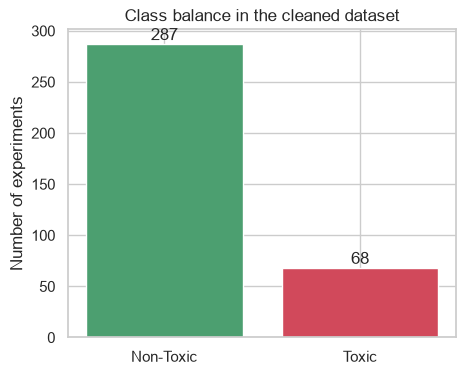

Only 19.2% of the samples are toxic.
A model that always says 'non-toxic' would already score 80.8% accuracy while being useless.


In [14]:
FIGS = PROJECT / "results" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

# --- Class balance -------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 4))
counts = clean[TARGET].value_counts().sort_index()
ax.bar(["Non-Toxic", "Toxic"], counts.values, color=["#4c9f70", "#d1495b"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 4, str(v), ha="center")
ax.set_ylabel("Number of experiments")
ax.set_title("Class balance in the cleaned dataset")
plt.show()

print(f"Only {clean[TARGET].mean() * 100:.1f}% of the samples are toxic.")
print("A model that always says 'non-toxic' would already score",
      f"{(1 - clean[TARGET].mean()) * 100:.1f}% accuracy while being useless.")

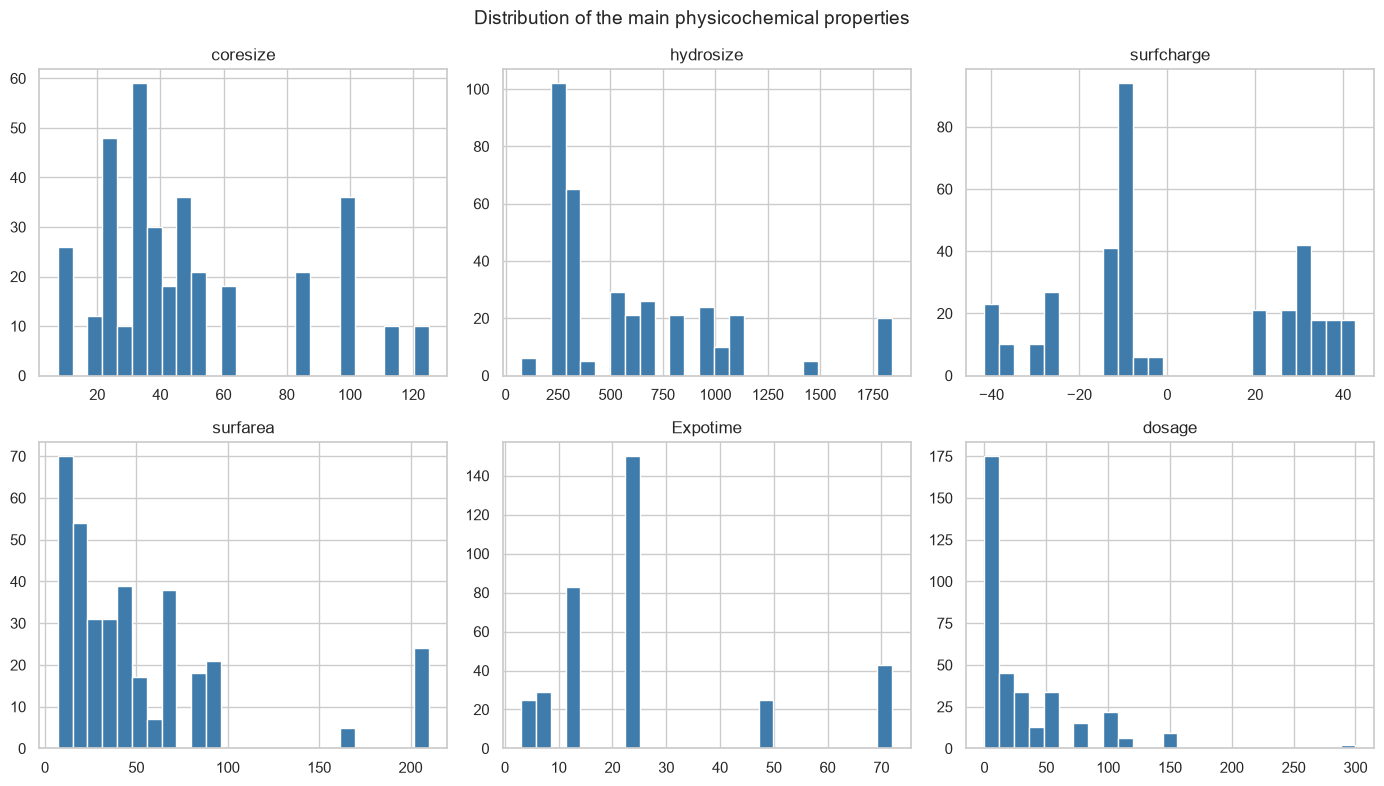

In [15]:
# --- Distribution of the six measurable properties -----------------
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), USER_INPUT_FEATURES):
    ax.hist(clean[col], bins=25, color="#3f7cac", edgecolor="white")
    ax.set_title(col)
fig.suptitle("Distribution of the main physicochemical properties", fontsize=14)
fig.tight_layout()
plt.show()

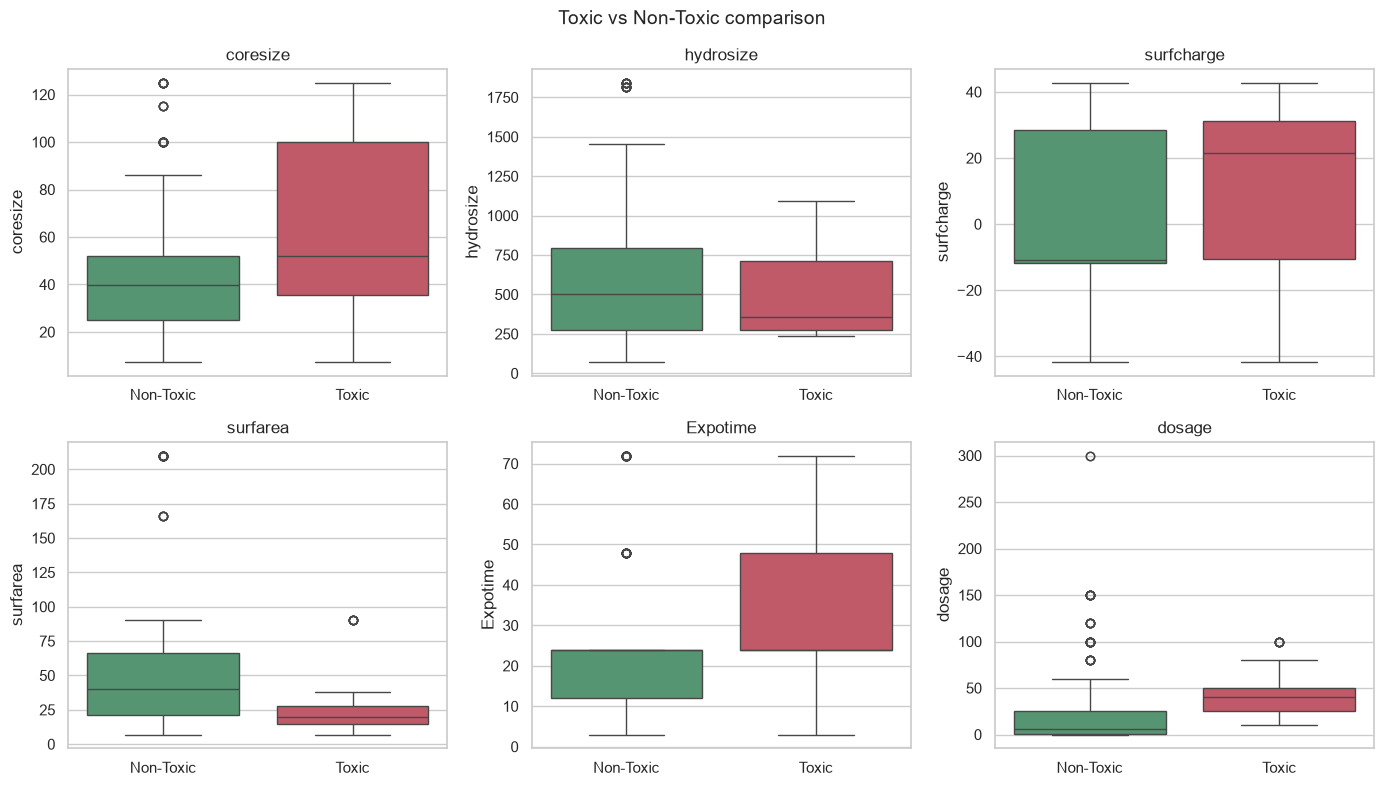

Toxic particles tend to have LONGER exposure times, HIGHER doses,
LARGER core size and SMALLER surface area.


In [16]:
# --- Toxic vs non-toxic, property by property ----------------------
tmp = clean.copy()
tmp["Toxicity"] = tmp[TARGET].map({0: "Non-Toxic", 1: "Toxic"})

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), USER_INPUT_FEATURES):
    sns.boxplot(data=tmp, x="Toxicity", y=col, ax=ax, hue="Toxicity",
                palette=["#4c9f70", "#d1495b"], legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Toxic vs Non-Toxic comparison", fontsize=14)
fig.tight_layout()
plt.show()

print("Toxic particles tend to have LONGER exposure times, HIGHER doses,")
print("LARGER core size and SMALLER surface area.")

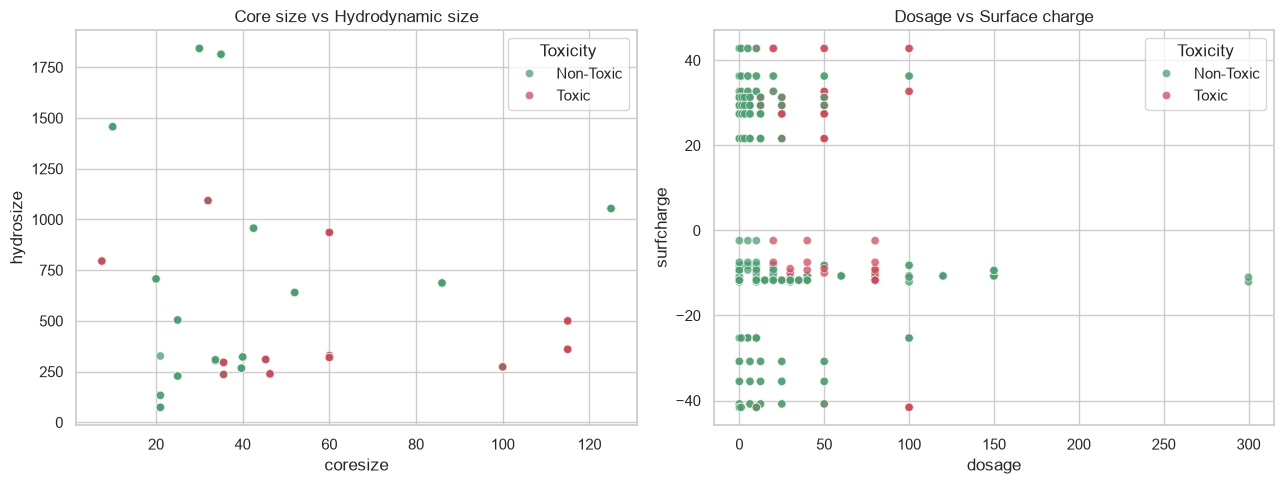

In [17]:
# --- Scatter plots -------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=tmp, x="coresize", y="hydrosize", hue="Toxicity",
                palette=["#4c9f70", "#d1495b"], alpha=0.75, ax=axes[0])
axes[0].set_title("Core size vs Hydrodynamic size")
sns.scatterplot(data=tmp, x="dosage", y="surfcharge", hue="Toxicity",
                palette=["#4c9f70", "#d1495b"], alpha=0.75, ax=axes[1])
axes[1].set_title("Dosage vs Surface charge")
fig.tight_layout()
plt.show()

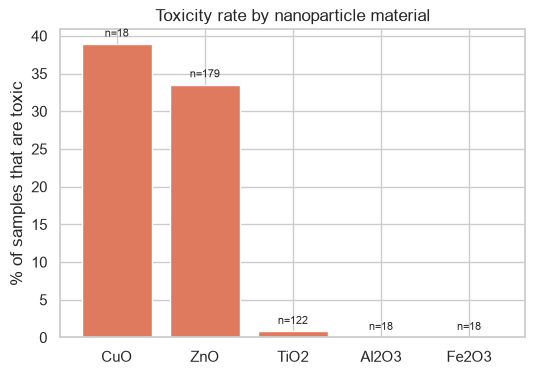

       Samples  Toxic  % toxic
NPs                           
CuO         18      7     38.9
ZnO        179     60     33.5
TiO2       122      1      0.8
Al2O3       18      0      0.0
Fe2O3       18      0      0.0

CuO and ZnO account for essentially all the toxicity.
This matches the chemistry - both dissolve and release metal ions.


In [18]:
# --- Toxicity rate per material ------------------------------------
rate = (clean.groupby("NPs")[TARGET]
        .agg(Samples="size", Toxic="sum"))
rate["% toxic"] = (rate["Toxic"] / rate["Samples"] * 100).round(1)
rate = rate.sort_values("% toxic", ascending=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(rate.index, rate["% toxic"], color="#e07a5f")
ax.set_ylabel("% of samples that are toxic")
ax.set_title("Toxicity rate by nanoparticle material")
for i, (pct, n) in enumerate(zip(rate["% toxic"], rate["Samples"])):
    ax.text(i, pct + 1, f"n={n}", ha="center", fontsize=8)
plt.show()

print(rate.to_string())
print()
print("CuO and ZnO account for essentially all the toxicity.")
print("This matches the chemistry - both dissolve and release metal ions.")

---
## Part 7 — Feature analysis

Which properties actually relate to toxicity?

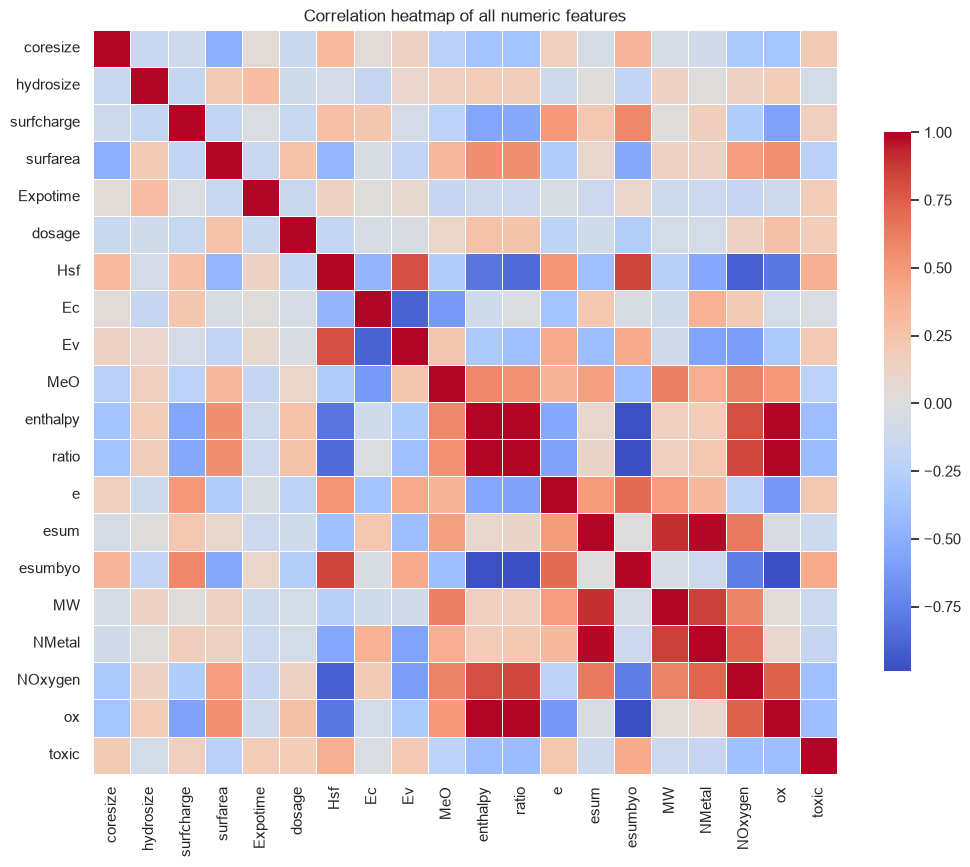

In [19]:
corr = clean[NUMERIC_FEATURES + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            linewidths=0.4, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation heatmap of all numeric features")
plt.show()

In [20]:
ranked = (corr[TARGET].drop(TARGET)
          .sort_values(key=abs, ascending=False)
          .rename("correlation_with_toxicity"))

print("Correlation of each feature with toxicity (strongest first):")
print(ranked.to_frame().to_string())
print()
print("The strongest signals are all MATERIAL-LEVEL chemistry descriptors")
print("(ratio, enthalpy, ox, Hsf) rather than particle geometry.")
print("In plain terms: what the particle is MADE OF matters more than its size.")

Correlation of each feature with toxicity (strongest first):
            correlation_with_toxicity
ratio                       -0.414873
enthalpy                    -0.410318
esumbyo                      0.406353
ox                          -0.399964
NOxygen                     -0.385582
Hsf                          0.383373
surfarea                    -0.241430
MeO                         -0.226789
e                            0.219611
Ev                           0.203680
coresize                     0.197262
Expotime                     0.190729
dosage                       0.176477
NMetal                      -0.163519
surfcharge                   0.156665
MW                          -0.126636
esum                        -0.115142
hydrosize                   -0.078825
Ec                          -0.031229

The strongest signals are all MATERIAL-LEVEL chemistry descriptors
(ratio, enthalpy, ox, Hsf) rather than particle geometry.
In plain terms: what the particle is MADE OF matters 

---
## Part 8 — Train / test split and the preprocessing pipeline

Two important choices here:

- **Stratified split**, so both halves keep the same toxic ratio. With only
  19% toxic samples, a plain random split could easily land very few toxic
  cases in the test set.
- **Scaling inside a `Pipeline`.** This matters: if we scaled the whole dataset
  before splitting, information from the test set would leak into the training
  set through the mean and standard deviation. Putting the scaler in a pipeline
  means it is fitted on the training fold only.

In [21]:
X = clean[FEATURES]
y = clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,          # keep the same toxic ratio in both halves
)

print(f"Training set : {len(X_train)} experiments  ({y_train.sum()} toxic)")
print(f"Test set     : {len(X_test)} experiments  ({y_test.sum()} toxic)")
print(f"Toxic rate    - train: {y_train.mean():.3f}   test: {y_test.mean():.3f}")

Training set : 266 experiments  (51 toxic)
Test set     : 89 experiments  (17 toxic)
Toxic rate    - train: 0.192   test: 0.191


In [22]:
def build_preprocessor():
    """Scale the numeric columns, one-hot encode the categorical one."""
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])


def make_pipeline(model):
    """Preprocessing + model as one object, so nothing leaks."""
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


print(build_preprocessor())

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['coresize', 'hydrosize', 'surfcharge',
                                  'surfarea', 'Expotime', 'dosage', 'Hsf', 'Ec',
                                  'Ev', 'MeO', 'enthalpy', 'ratio', 'e', 'esum',
                                  'esumbyo', 'MW', 'NMetal', 'NOxygen', 'ox']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Celltype'])])


---
## Part 9 — Model training

The five classifiers named in our abstract.

**Why `class_weight="balanced"`?** Only 19% of samples are toxic. Without it
the models simply learn to answer "non-toxic" to everything, which still scores
about 81% accuracy while catching zero toxic particles. Balancing the class
weights forces them to pay attention to the minority class.

In [23]:
def get_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "SVM": SVC(kernel="rbf", probability=True,
                   class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1),
    }


for name, model in get_models().items():
    print(f"{name:22s} {type(model).__name__}")

Logistic Regression    LogisticRegression
Decision Tree          DecisionTreeClassifier
KNN                    KNeighborsClassifier
SVM                    SVC
Random Forest          RandomForestClassifier


In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fitted = {}
rows = []

for name, model in get_models().items():
    pipe = make_pipeline(model)
    pipe.fit(X_train, y_train)          # <-- training happens here
    fitted[name] = pipe

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    cv_f1 = cross_val_score(make_pipeline(model), X_train, y_train,
                            cv=cv, scoring="f1")

    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall":    recall_score(y_test, y_pred, zero_division=0),
        "F1":        f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC":   roc_auc_score(y_test, y_prob),
        "CV_F1_mean": cv_f1.mean(),
        "CV_F1_std":  cv_f1.std(),
    })
    print(f"trained: {name}")

print("\nAll five models trained.")

trained: Logistic Regression
trained: Decision Tree


trained: KNN


trained: SVM


trained: Random Forest

All five models trained.


---
## Part 10 — Evaluation

Per-model classification reports, then the comparison table, confusion
matrices and ROC curves.

In [25]:
for name, pipe in fitted.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pipe.predict(X_test),
                                target_names=["Non-Toxic", "Toxic"],
                                zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

   Non-Toxic       0.96      0.90      0.93        72
       Toxic       0.67      0.82      0.74        17

    accuracy                           0.89        89
   macro avg       0.81      0.86      0.83        89
weighted avg       0.90      0.89      0.89        89

Decision Tree
              precision    recall  f1-score   support

   Non-Toxic       0.96      0.94      0.95        72
       Toxic       0.78      0.82      0.80        17

    accuracy                           0.92        89
   macro avg       0.87      0.88      0.88        89
weighted avg       0.92      0.92      0.92        89

KNN
              precision    recall  f1-score   support

   Non-Toxic       0.88      0.99      0.93        72
       Toxic       0.88      0.41      0.56        17

    accuracy                           0.88        89
   macro avg       0.88      0.70      0.74        89
weighted avg       0.88      0.88   

In [26]:
results = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
print("MODEL COMPARISON (sorted by F1)")
results.round(3)

MODEL COMPARISON (sorted by F1)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_F1_mean,CV_F1_std
0,Random Forest,0.944,0.800,0.941,0.865,0.946,0.880,0.057
1,Decision Tree,0.921,0.778,0.824,0.800,0.904,0.831,0.057
2,Logistic Regression,0.888,0.667,0.824,0.737,0.931,0.695,0.098
3,SVM,0.865,0.609,0.824,0.700,0.928,0.665,0.078
4,KNN,0.876,0.875,0.412,0.560,0.836,0.527,0.114


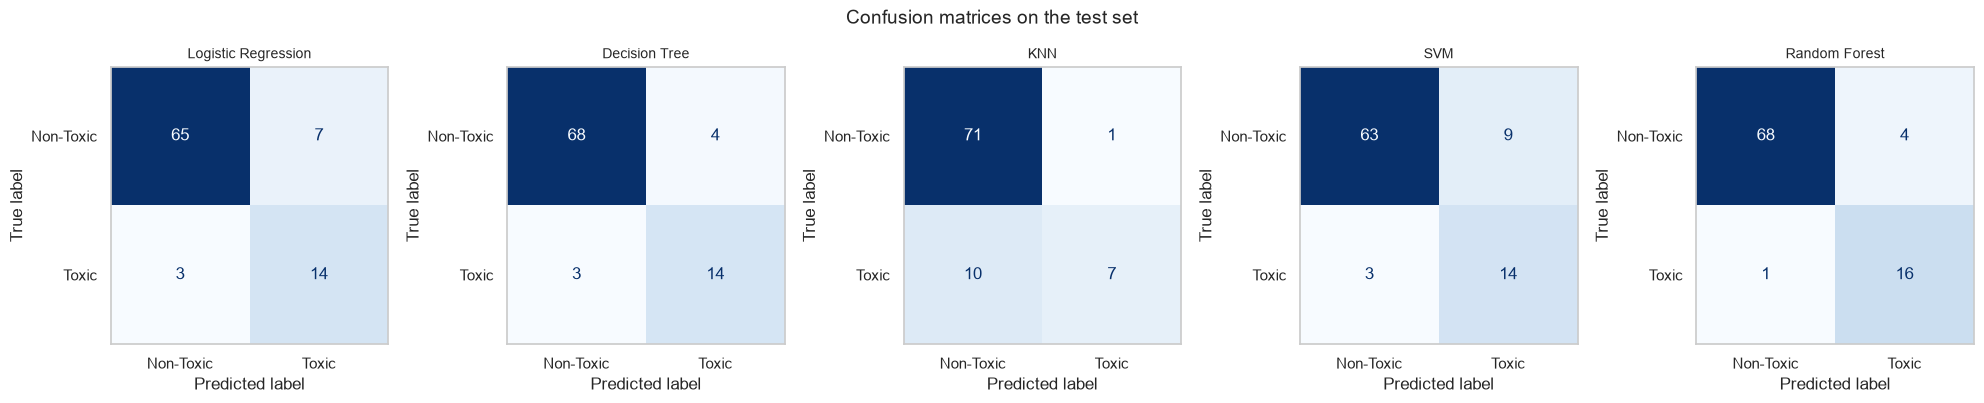

Reading a confusion matrix: the bottom-left cell is a TOXIC particle
that the model called safe. That is the dangerous kind of error.


In [27]:
# --- Confusion matrices --------------------------------------------
fig, axes = plt.subplots(1, len(fitted), figsize=(4 * len(fitted), 4))
for ax, (name, pipe) in zip(np.atleast_1d(axes), fitted.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Non-Toxic", "Toxic"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
    ax.grid(False)
fig.suptitle("Confusion matrices on the test set", fontsize=14)
fig.tight_layout()
plt.show()

print("Reading a confusion matrix: the bottom-left cell is a TOXIC particle")
print("that the model called safe. That is the dangerous kind of error.")

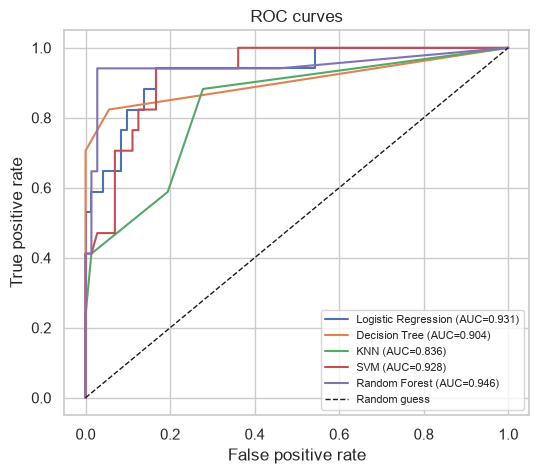

In [28]:
# --- ROC curves ----------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in fitted.items():
    prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves")
ax.legend(fontsize=8)
plt.show()

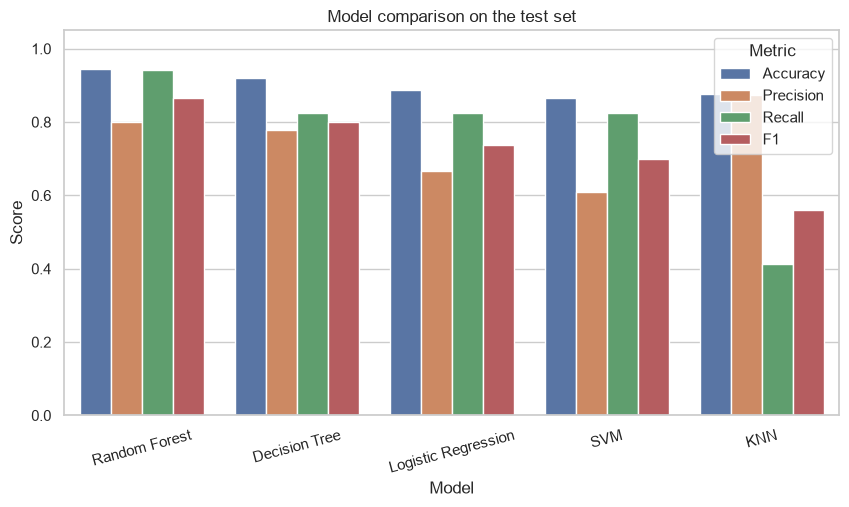

In [29]:
# --- Metric comparison bar chart -----------------------------------
melted = results.melt(id_vars="Model",
                      value_vars=["Accuracy", "Precision", "Recall", "F1"],
                      var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=melted, x="Model", y="Score", hue="Metric", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("Model comparison on the test set")
ax.tick_params(axis="x", rotation=15)
plt.show()

---
## Part 11 — Selecting the best model

We select by **F1 score, not accuracy**.

Look at KNN in the table above: it reaches a respectable-looking accuracy, but
its recall is only ~0.41, meaning it misses nearly 60% of the toxic particles.
For a safety screening tool that is the worst possible failure mode. F1
balances precision and recall, so it will not reward a model that simply
ignores the minority class.

In [30]:
best_name = results.iloc[0]["Model"]
best_row = results.iloc[0]

print("=" * 55)
print(f"  BEST MODEL: {best_name}")
print("=" * 55)
print(f"  Accuracy  : {best_row['Accuracy']:.3f}")
print(f"  Precision : {best_row['Precision']:.3f}")
print(f"  Recall    : {best_row['Recall']:.3f}   <- catches this share of toxic particles")
print(f"  F1        : {best_row['F1']:.3f}")
print(f"  ROC-AUC   : {best_row['ROC_AUC']:.3f}")
print("=" * 55)

# Save the comparison table
res_dir = PROJECT / "results"
res_dir.mkdir(parents=True, exist_ok=True)
results.to_csv(res_dir / "model_comparison.csv", index=False)
print("\nSaved:", res_dir / "model_comparison.csv")

  BEST MODEL: Random Forest
  Accuracy  : 0.944
  Precision : 0.800
  Recall    : 0.941   <- catches this share of toxic particles
  F1        : 0.865
  ROC-AUC   : 0.946

Saved: C:\Users\Dhyey's Laptop\Claude_Cowork\nanoparticle-toxicity\results\model_comparison.csv


---
## Part 12 — Interpretation: which features matter?

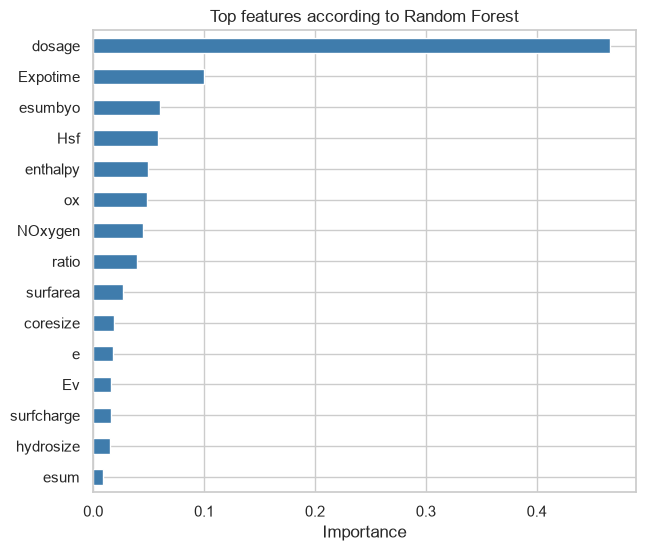

          importance
dosage      0.465986
Expotime    0.099949
esumbyo     0.060098
Hsf         0.058823
enthalpy    0.049567
ox          0.048345
NOxygen     0.044518
ratio       0.039778
surfarea    0.026768
coresize    0.019006


In [31]:
best_pipe = fitted[best_name]
model = best_pipe.named_steps["model"]

if hasattr(model, "feature_importances_"):
    names = [n.split("__", 1)[-1]
             for n in best_pipe.named_steps["prep"].get_feature_names_out()]
    imp = pd.Series(model.feature_importances_, index=names).sort_values()

    fig, ax = plt.subplots(figsize=(7, 6))
    imp[-15:].plot(kind="barh", ax=ax, color="#3f7cac")
    ax.set_xlabel("Importance")
    ax.set_title(f"Top features according to {best_name}")
    plt.show()

    print(imp.sort_values(ascending=False).head(10).to_frame("importance").to_string())
else:
    print(f"{best_name} has no feature_importances_ attribute.")

**What the model is telling us**

- The chemical identity of the material dominates. The descriptors that encode
  *which* oxide it is are the most informative features.
- Among the properties an experimenter can control, **dosage**, **exposure
  time** and **surface area** carry the most weight.
- Hydrodynamic size is almost uninformative here.
- Practical takeaway: choosing a safer base material matters more than
  fine-tuning the particle size.

---
## Part 13 — Honesty check: leave-one-material-out

This check was not in our original plan. We added it after the EDA.

Almost every toxic sample is CuO or ZnO, and 13 of the 19 numeric features are
**constant within a material**. So a normal random split lets the model partly
*recognise the material* rather than learn the underlying chemistry — and the
reported accuracy would be optimistic for a genuinely new nanoparticle.

To measure this, we train on 4 materials and test on the 5th, which the model
has never seen at all.

In [32]:
logo = LeaveOneGroupOut()
group_rows = []

for train_idx, test_idx in logo.split(X, y, clean["NPs"]):
    material = clean["NPs"].iloc[test_idx].iloc[0]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    if y_tr.nunique() < 2:          # cannot train on a single class
        group_rows.append({"Held_out_material": material, "n_samples": len(test_idx),
                           "n_toxic": int(y_te.sum()), "Accuracy": np.nan,
                           "Recall_toxic": np.nan})
        continue

    pipe = make_pipeline(get_models()[best_name])
    pipe.fit(X.iloc[train_idx], y_tr)
    pred = pipe.predict(X.iloc[test_idx])

    group_rows.append({
        "Held_out_material": material,
        "n_samples": len(test_idx),
        "n_toxic": int(y_te.sum()),
        "Accuracy": accuracy_score(y_te, pred),
        "Recall_toxic": recall_score(y_te, pred, zero_division=0) if y_te.sum() else np.nan,
    })

lomo = pd.DataFrame(group_rows)
lomo.to_csv(res_dir / "leave_one_material_out.csv", index=False)
print(lomo.round(3).to_string(index=False))
print()
print(f"Normal test accuracy      : {best_row['Accuracy']:.3f}")
print(f"Held-out ZnO accuracy     : {lomo.set_index('Held_out_material').loc['ZnO', 'Accuracy']:.3f}")
print()
print("CONCLUSION: the model does clearly worse on a material it has never")
print("seen. It should be used for materials similar to the five it was")
print("trained on, not for a brand new nanoparticle. This is a limitation of")
print("the dataset (only 5 materials), not of the code.")

Held_out_material  n_samples  n_toxic  Accuracy  Recall_toxic
            Al2O3         18        0     1.000           NaN
              CuO         18        7     0.889         0.714
            Fe2O3         18        0     1.000           NaN
             TiO2        122        1     0.992         0.000
              ZnO        179       60     0.771         0.717

Normal test accuracy      : 0.944
Held-out ZnO accuracy     : 0.771

CONCLUSION: the model does clearly worse on a material it has never
seen. It should be used for materials similar to the five it was
trained on, not for a brand new nanoparticle. This is a limitation of
the dataset (only 5 materials), not of the code.


---
## Part 14 — Save the final model

The winner is retrained on **all** the data (not just the training split), so
the deployed model uses every experiment we have.

In [33]:
final_pipe = make_pipeline(get_models()[best_name])
final_pipe.fit(X, y)

model_dir = PROJECT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "pipeline": final_pipe,
    "model_name": best_name,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "feature_order": FEATURES,      # so columns are never fed in the wrong order
}, model_dir / "best_model.joblib")

print(f"Saved {best_name} to {model_dir / 'best_model.joblib'}")
print(f"Trained on all {len(X)} experiments.")

Saved Random Forest to C:\Users\Dhyey's Laptop\Claude_Cowork\nanoparticle-toxicity\models\best_model.joblib
Trained on all 355 experiments.


---
## Part 15 — The prediction system

The user supplies only the **6 measurable properties** plus the material name.
The 13 chemistry descriptors are looked up automatically.

Note `X = X[bundle["feature_order"]]` — this reindexes the columns into the
exact order used during training. Without it, a dictionary written in a
different order would silently feed core size in as dosage, and the model would
return a confident but wrong answer with no error at all.

In [34]:
def predict_toxicity(material, values, celltype="Cancer",
                     bundle=None, lookup=None):
    """Predict TOXIC / NON-TOXIC for one nanoparticle."""
    bundle = bundle or joblib.load(model_dir / "best_model.joblib")
    lookup = material_lookup if lookup is None else lookup

    # --- validate the input ---
    if material not in lookup.index:
        raise ValueError(f"Unknown material '{material}'. "
                         f"Known: {', '.join(lookup.index)}")
    if celltype not in ("Cancer", "Normal"):
        raise ValueError(f"Cell type must be 'Cancer' or 'Normal', got '{celltype}'")
    missing = [c for c in USER_INPUT_FEATURES if c not in values]
    if missing:
        raise ValueError(f"Missing properties: {', '.join(missing)}")

    # --- build the row: user values + material chemistry ---
    row = dict(values)
    row.update(lookup.loc[material].to_dict())
    row["Celltype"] = celltype

    X_one = pd.DataFrame([row])[bundle["feature_order"]]   # correct column order

    label = int(bundle["pipeline"].predict(X_one)[0])
    prob = float(bundle["pipeline"].predict_proba(X_one)[0][1])
    return label, prob


bundle = joblib.load(model_dir / "best_model.joblib")
print("Prediction function ready. Model:", bundle["model_name"])

Prediction function ready. Model: Random Forest


In [35]:
# --- Worked examples -----------------------------------------------
examples = [
    ("ZnO",   dict(coresize=40, hydrosize=300, surfcharge=-12,
                   surfarea=50, Expotime=24, dosage=100), "Cancer"),
    ("CuO",   dict(coresize=30, hydrosize=400, surfcharge=-20,
                   surfarea=30, Expotime=48, dosage=200), "Cancer"),
    ("TiO2",  dict(coresize=25, hydrosize=200, surfcharge=15,
                   surfarea=90, Expotime=24, dosage=10), "Normal"),
    ("Al2O3", dict(coresize=39.7, hydrosize=267, surfcharge=36.3,
                   surfarea=64.7, Expotime=24, dosage=0.01), "Normal"),
]

print(f"{'Material':10s} {'Dose':>8s}  {'Cell':8s} {'Prediction':12s} {'P(toxic)':>9s}")
print("-" * 56)
for material, values, celltype in examples:
    label, prob = predict_toxicity(material, values, celltype, bundle)
    verdict = "TOXIC" if label else "NON-TOXIC"
    print(f"{material:10s} {values['dosage']:>8} "
          f"{celltype:8s} {verdict:12s} {prob * 100:>8.1f}%")

print()
print("These match the known chemistry: CuO and ZnO release toxic metal ions,")
print("while TiO2 and Al2O3 are largely inert.")

Material       Dose  Cell     Prediction    P(toxic)
--------------------------------------------------------


ZnO             100 Cancer   TOXIC            99.0%
CuO             200 Cancer   TOXIC            96.7%


TiO2             10 Normal   NON-TOXIC         1.3%
Al2O3          0.01 Normal   NON-TOXIC         0.0%

These match the known chemistry: CuO and ZnO release toxic metal ions,
while TiO2 and Al2O3 are largely inert.


In [36]:
# --- The input validation actually works ---------------------------
for bad_call, description in [
    (lambda: predict_toxicity("Gold", dict(coresize=40, hydrosize=300,
        surfcharge=-12, surfarea=50, Expotime=24, dosage=100), "Cancer", bundle),
     "unknown material"),
    (lambda: predict_toxicity("ZnO", dict(coresize=40), "Cancer", bundle),
     "missing properties"),
    (lambda: predict_toxicity("ZnO", dict(coresize=40, hydrosize=300,
        surfcharge=-12, surfarea=50, Expotime=24, dosage=100), "Alien", bundle),
     "invalid cell type"),
]:
    try:
        bad_call()
        print(f"NO ERROR for {description}  <-- this would be a bug")
    except ValueError as err:
        print(f"correctly rejected ({description}): {err}")

correctly rejected (unknown material): Unknown material 'Gold'. Known: Al2O3, CuO, Fe2O3, TiO2, ZnO
correctly rejected (missing properties): Missing properties: hydrosize, surfcharge, surfarea, Expotime, dosage
correctly rejected (invalid cell type): Cell type must be 'Cancer' or 'Normal', got 'Alien'


---
## Verification — does this notebook match the `src/` pipeline?

This notebook re-implements the pipeline as a readable walkthrough. That means
there are now two copies of the logic, which could drift apart.

The cell below re-runs the real pipeline's saved results and checks the numbers
are identical. If anyone edits one side and not the other, this cell fails.

In [37]:
pipeline_results = PROJECT / "results" / "model_comparison.csv"

# The notebook just overwrote this file, so compare against a fresh run
# of the src/ pipeline instead.
import subprocess
import sys

proc = subprocess.run([sys.executable, "train_models.py"],
                      cwd=PROJECT / "src", capture_output=True, text=True)
print("src/train_models.py exit code:", proc.returncode)

pipeline_table = pd.read_csv(pipeline_results).set_index("Model").sort_index()
notebook_table = results.set_index("Model").sort_index()

cols = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
diff = (pipeline_table[cols] - notebook_table[cols]).abs().max().max()

print(f"\nLargest difference between notebook and pipeline: {diff:.10f}")
assert diff < 1e-9, "Notebook and src/ pipeline disagree!"
print("MATCH - the notebook reproduces the pipeline exactly.")
print()
print(pipeline_table[cols].round(3).to_string())

src/train_models.py exit code: 0

Largest difference between notebook and pipeline: 0.0000000000
MATCH - the notebook reproduces the pipeline exactly.

                     Accuracy  Precision  Recall     F1  ROC_AUC
Model                                                           
Decision Tree           0.921      0.778   0.824  0.800    0.904
KNN                     0.876      0.875   0.412  0.560    0.836
Logistic Regression     0.888      0.667   0.824  0.737    0.931
Random Forest           0.944      0.800   0.941  0.865    0.946
SVM                     0.865      0.609   0.824  0.700    0.928


---
## Summary

| Stage | Result |
|---|---|
| Raw dataset | 483 experiments |
| After cleaning and replicate merging | **355 unique experiments** |
| Toxic / non-toxic | 68 / 287 (19% toxic) |
| Models compared | 5 |
| **Best model** | **Random Forest** |
| Accuracy | 0.944 |
| Recall on toxic | 0.941 |
| F1 | 0.865 |
| ROC-AUC | 0.946 |

**Two data problems we had to catch:**

1. `viability` leaks the label — it is what the toxic/non-toxic class was
   derived from. Excluded.
2. 122 replicate experiments become identical once `viability` is dropped, so a
   random split was putting the same experiment in both train and test. Merged
   into one row each.

**The honest limitation:** held-out ZnO accuracy is 0.771 against 0.944 on the
normal split, because only 5 materials are represented. The model works for
materials similar to those it has seen, not for genuinely new ones.